In [ ]:
from google.colab import files

uploaded = files.upload()

Saving balanced_predictive_maintenance.xlsx to balanced_predictive_maintenance.xlsx


In [ ]:
import os

os.listdir()

['.config', 'balanced_predictive_maintenance.xlsx', 'drive', 'sample_data']

In [ ]:
import pandas as pd

df = pd.read_excel(
    "balanced_predictive_maintenance.xlsx"
)

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,8609,L55788,L,297.4,308.4,1369,50.6,220,1,Overstrain Failure
1,3878,H33291,H,302.6,311.7,1471,48.3,25,0,No Failure
2,6254,L53433,L,300.9,310.4,1615,30.9,200,0,No Failure
3,1111,L48290,L,296.5,307.4,1292,52.5,62,0,No Failure
4,7742,L54921,L,300.5,312.0,1478,39.0,153,0,No Failure


In [ ]:
!pip install openpyxl

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


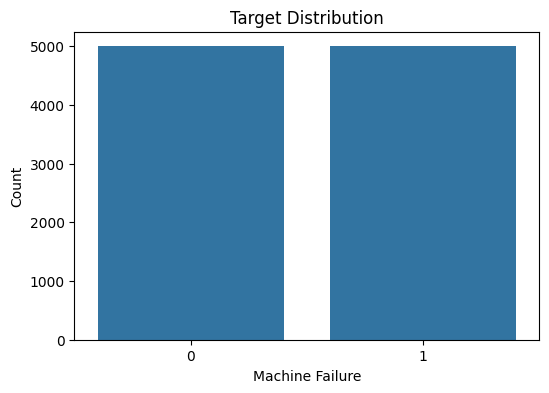

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(
    x='Target',
    data=df
)

plt.title("Target Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Count")

plt.show()

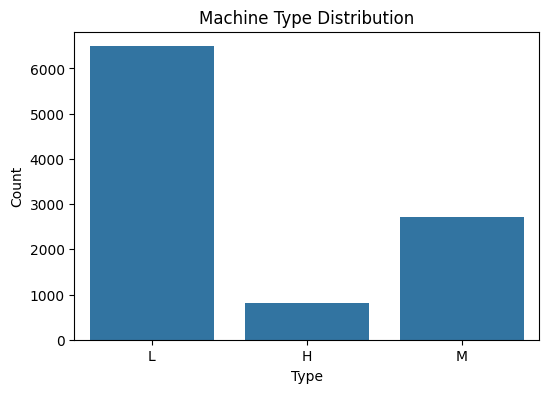

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='Type',
    data=df
)

plt.title("Machine Type Distribution")
plt.xlabel("Type")
plt.ylabel("Count")

plt.show()

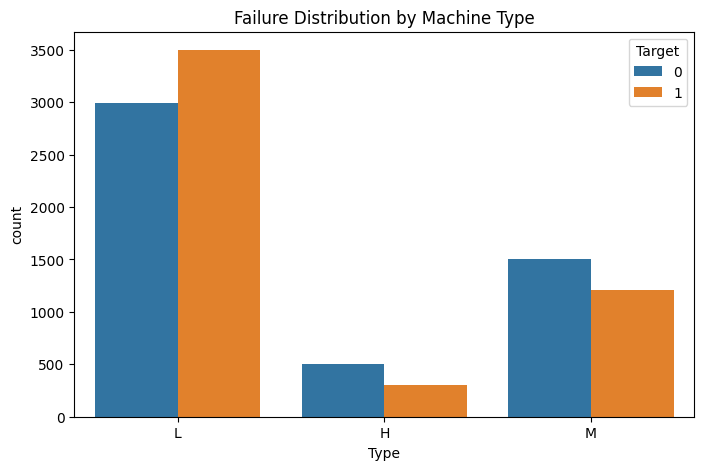

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Type',
    hue='Target',
    data=df
)

plt.title("Failure Distribution by Machine Type")

plt.show()

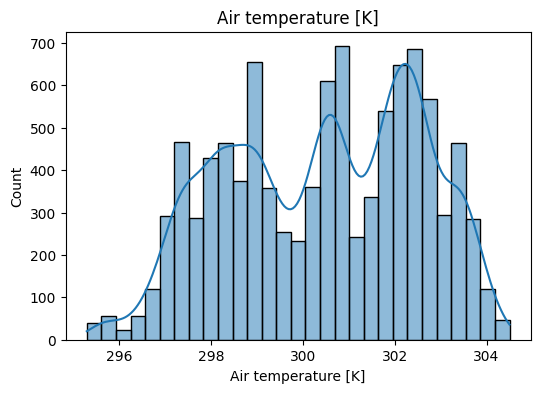

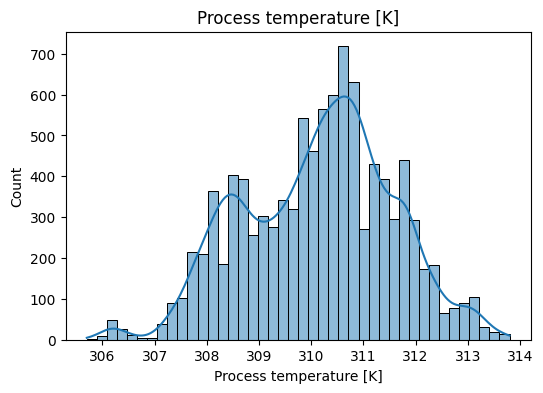

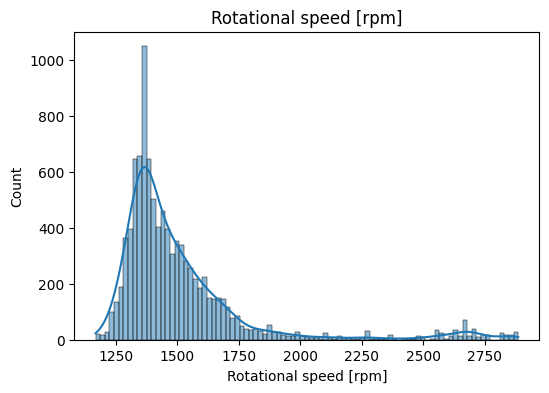

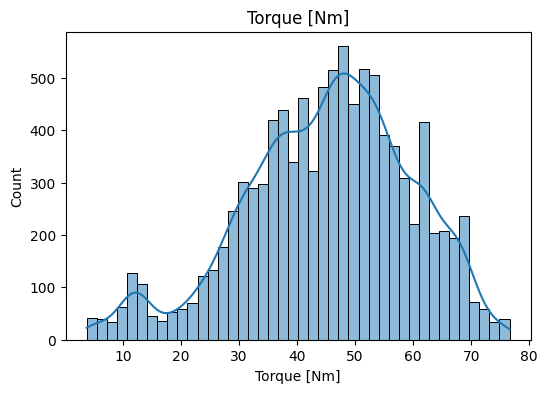

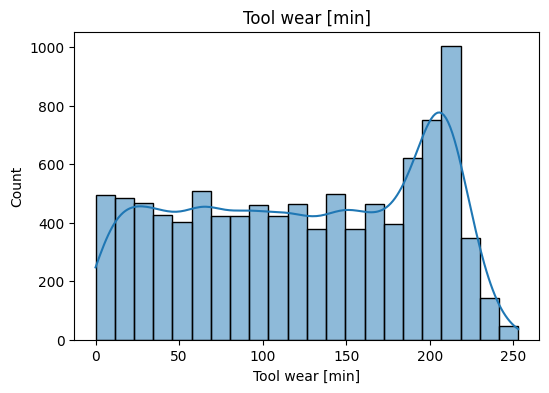

In [ ]:
numerical_columns = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for column in numerical_columns:

    plt.figure(figsize=(6,4))

    sns.histplot(
        df[column],
        kde=True
    )

    plt.title(column)

    plt.show()

**Testing** **Models**

Logistic Regression

Logistic Regression Accuracy: 0.821
              precision    recall  f1-score   support

           0       0.83      0.81      0.82      1000
           1       0.81      0.83      0.82      1000

    accuracy                           0.82      2000
   macro avg       0.82      0.82      0.82      2000
weighted avg       0.82      0.82      0.82      2000



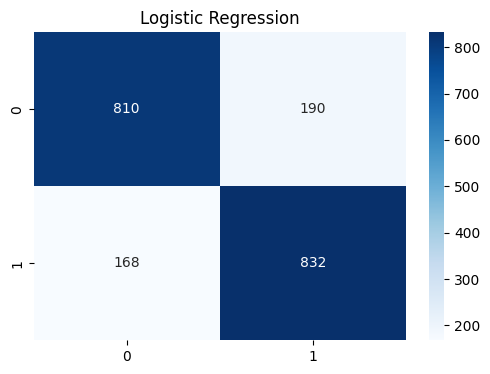

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split
import pandas as pd

X = df.drop(columns=['UDI', 'Product ID', 'Failure Type', 'Target'])
y = df['Target']

X = pd.get_dummies(X, columns=['Type'], drop_first=True)

X.columns = X.columns.str.replace(r'[\\[\\]<>]', '', regex=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

lr_model = LogisticRegression(
    max_iter=1000
)

lr_model.fit(
    X_train,
    y_train
)
lr_pred = lr_model.predict(
    X_test
)
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

print("Logistic Regression Accuracy:", lr_accuracy)
print(
    classification_report(
        y_test,
        lr_pred
    )
)
lr_cm = confusion_matrix(
    y_test,
    lr_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Logistic Regression")

plt.show()

Random Forest

Random Forest Accuracy: 0.991
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1000
           1       0.98      1.00      0.99      1000

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



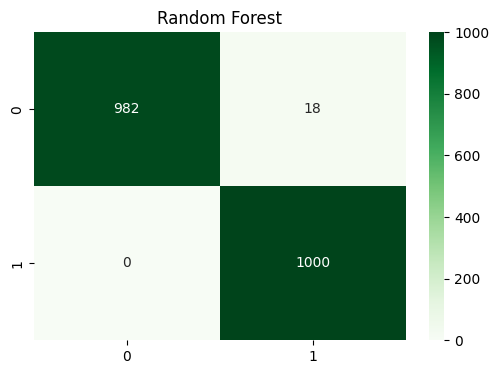

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)
rf_pred = rf_model.predict(
    X_test
)
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest Accuracy:", rf_accuracy)
print(
    classification_report(
        y_test,
        rf_pred
    )
)
rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Random Forest")

plt.show()

XG Boost

XGBoost Accuracy: 0.9895
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1000
           1       0.98      1.00      0.99      1000

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



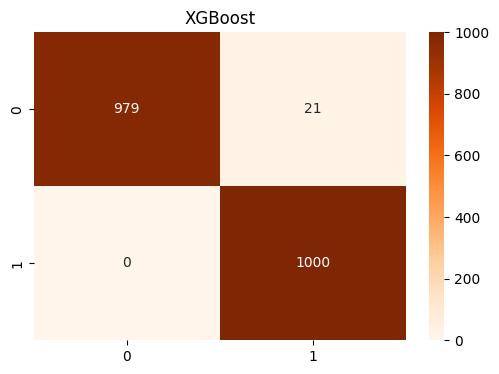

In [ ]:
!pip install xgboost
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
X_train.columns = X_train.columns.str.replace(r'[^A-Za-z0-9_]+', '_', regex=True)
X_test.columns = X_test.columns.str.replace(r'[^A-Za-z0-9_]+', '_', regex=True)

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(
    X_train,
    y_train
)
xgb_pred = xgb_model.predict(
    X_test
)
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

print("XGBoost Accuracy:", xgb_accuracy)
print(
    classification_report(
        y_test,
        xgb_pred
    )
)
xgb_cm = confusion_matrix(
    y_test,
    xgb_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title("XGBoost")

plt.show()

Final Model Comparision

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        lr_accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

print(results)

                 Model  Accuracy
0  Logistic Regression    0.8210
1        Random Forest    0.9910
2              XGBoost    0.9895


Comaparision Graph

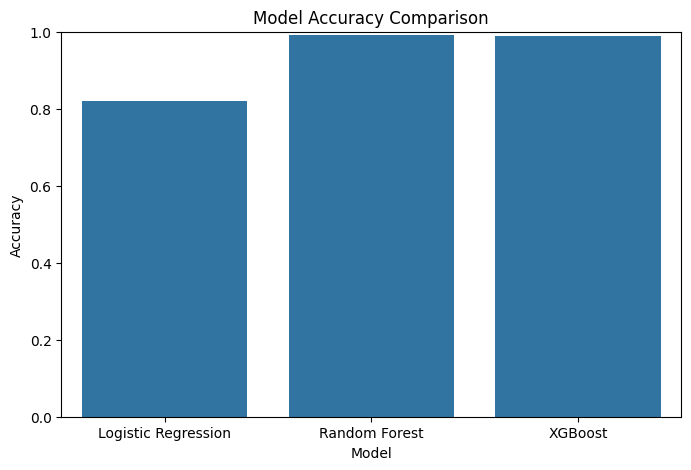

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results
)

plt.title("Model Accuracy Comparison")

plt.ylim(0,1)

plt.show()

In [ ]:
# Correlation with Target

correlation_target = df.corr(numeric_only=True)['Target']

print(correlation_target.sort_values(ascending=False))

Target                     1.000000
Torque [Nm]                0.378964
Tool wear [min]            0.261131
Air temperature [K]        0.219846
Process temperature [K]    0.096675
UDI                       -0.056010
Rotational speed [rpm]    -0.086043
Name: Target, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import MinMaxScaler

lr = lr_model
rf = rf_model
xgb = xgb_model

feature_names = X_train.columns

lr_importance = np.abs(lr.coef_[0])
rf_importance = rf.feature_importances_
xgb_importance = xgb.feature_importances_

In [ ]:
scaler = MinMaxScaler()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Logistic Regression': scaler.fit_transform(lr_importance.reshape(-1, 1)).flatten(),
    'Random Forest': scaler.fit_transform(rf_importance.reshape(-1, 1)).flatten(),
    'XGBoost': scaler.fit_transform(xgb_importance.reshape(-1, 1)).flatten()
})

importance_melted = pd.melt(
    importance_df,
    id_vars=['Feature'],
    var_name='Model',
    value_name='Normalized Importance'
)

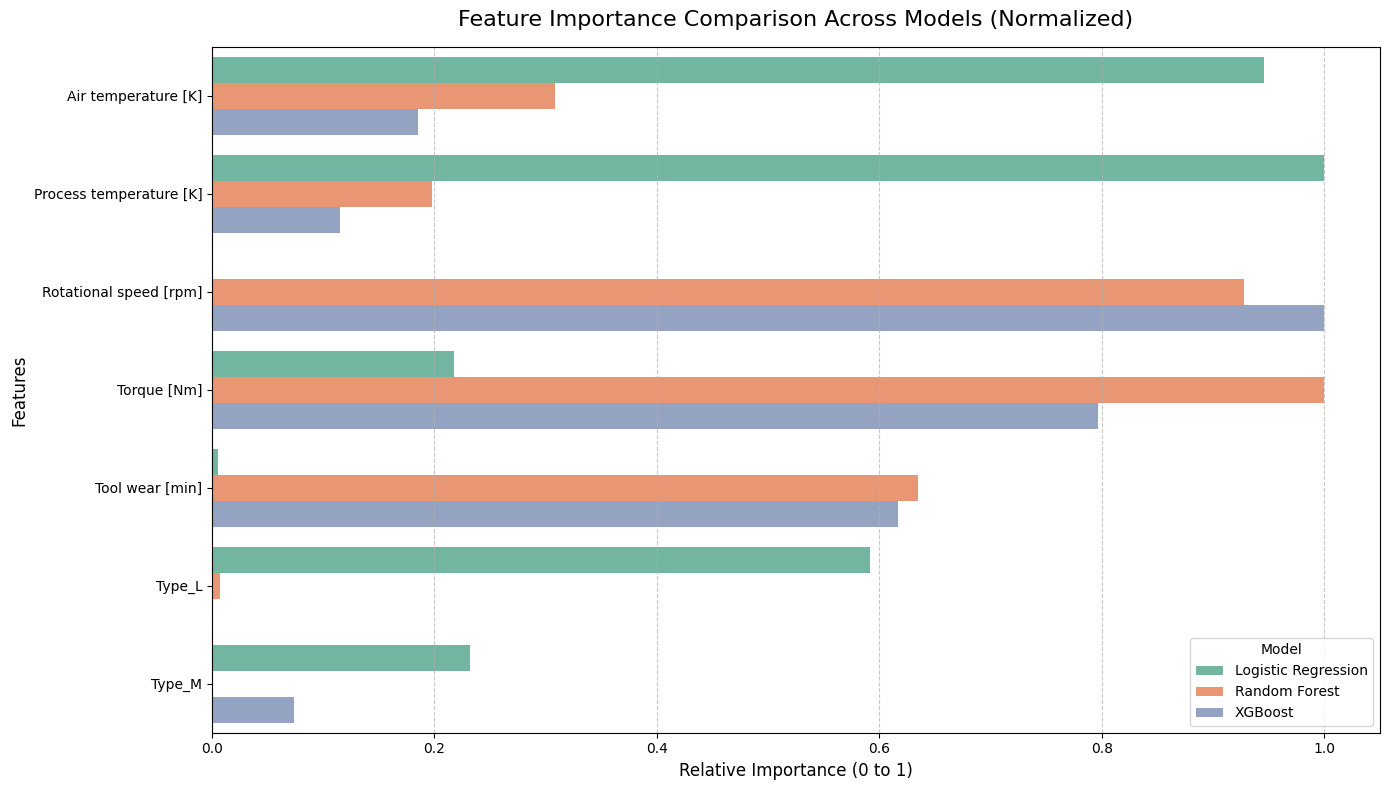

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.barplot(
    data=importance_melted,
    x='Normalized Importance',
    y='Feature',
    hue='Model',
    palette='Set2'
)

plt.title('Feature Importance Comparison Across Models (Normalized)', fontsize=16, pad=15)
plt.xlabel('Relative Importance (0 to 1)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()